# Лабораторна робота № 4
## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень (датасет Annealing)

**Мета:** порівняти Decision Tree, Random Forest та градієнтний бустинг (XGBoost) на датасеті *Annealing* з пропусками; дослідити вплив способу обробки пропусків, коректно підібрати гіперпараметри (Optuna, без витоку даних), неупереджено оцінити моделі (вкладена CV), статистично порівняти їх (скоригований тест Наде–Бенжіо) та інтерпретувати (MDI, permutation importance, SHAP).

**Примітки до реалізації**
* Датасет завантажується з OpenML через `sklearn.datasets.fetch_openml` (версія 1, 898 спостережень). Моделі: `DecisionTreeClassifier`, `RandomForestClassifier` (scikit-learn) та `XGBClassifier` (`XGB`); цільова змінна кодується `LabelEncoder`.
* Усі джерела випадковості ініціалізуються однією константою `SEED = 42 + N` (тут `SEED = 43`).
* Імпутація виконується **лише всередині `Pipeline`**, тож витоку даних немає; тестова вибірка використовується один раз, у п. 3.6–3.8.

In [1]:
import warnings, subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

import sklearn, scipy, optuna, shap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_score, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200)

N_STUDENT = 1            # <-- ВКАЖІТЬ СВІЙ НОМЕР У СПИСКУ ГРУПИ
SEED = 42 + N_STUDENT
N_TRIALS = 30            # кількість спроб Optuna (можна зменшити для швидшого запуску)
np.random.seed(SEED)

# фіксація версій (requirements.txt)
with open('requirements.txt', 'w') as f:
    f.write(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze']).decode())
print(f'SEED = {SEED}')
for lib in (sys, np, pd, scipy, sklearn, optuna, shap):
    print(getattr(lib, '__name__'), getattr(lib, '__version__', sys.version.split()[0]))

/home/roman/Documents/university/machine-learning/lab-4/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SEED = 43
sys 3.12.4
numpy 2.5.4
pandas 3.0.6
scipy 1.18.1
sklearn 1.9.1
optuna 5.0.0
shap 0.54.1


## 3.1 Первинний аналіз даних

In [2]:
data = fetch_openml(name='anneal', version=1, as_frame=True)
X, y = data.data.copy(), data.target.copy()

# категоріальні ознаки -> object (пропуски як np.nan)
for col in X.columns:
    if not pd.api.types.is_numeric_dtype(X[col]):
        X[col] = X[col].astype(object).where(X[col].notna(), np.nan)
y = y.astype(str)

print(f'Версія датасету: OpenML anneal v1, спостережень: {X.shape[0]}, ознак: {X.shape[1]}')
print('Типи ознак:', X.dtypes.map(lambda t: 'числова' if pd.api.types.is_numeric_dtype(t) else 'категоріальна').value_counts().to_dict())

Версія датасету: OpenML anneal v1, спостережень: 898, ознак: 38
Типи ознак: {'категоріальна': 32, 'числова': 6}


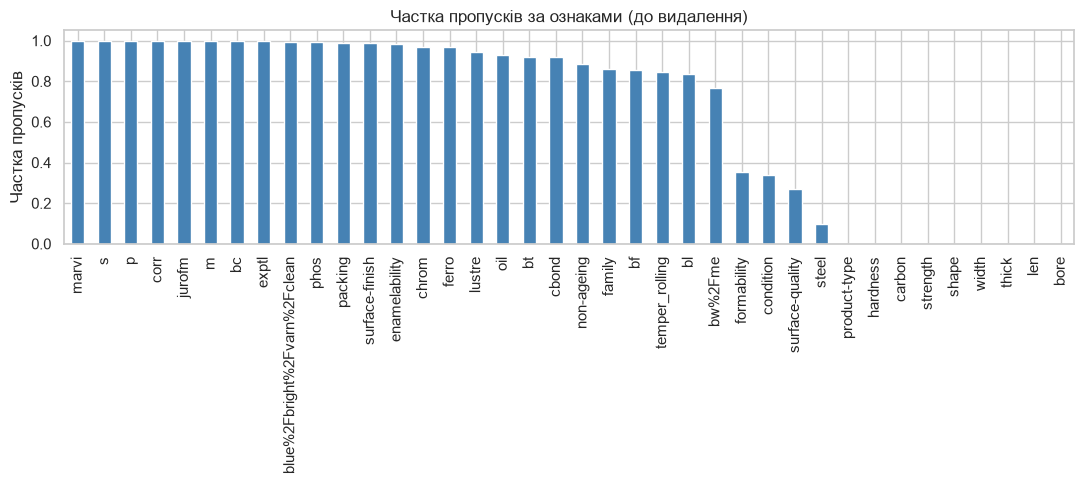

Повністю порожні (видаляємо): ['marvi', 's', 'p', 'corr', 'jurofm', 'm']
Константні без пропусків (видаляємо): ['product-type']
Лишилось ознак: 31
Ознаки з пропусками: 23


In [3]:
miss = X.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
miss.plot.bar(ax=ax, color='steelblue')
ax.set_ylabel('Частка пропусків'); ax.set_title('Частка пропусків за ознаками (до видалення)')
plt.tight_layout(); plt.show()

empty_cols = miss[miss == 1.0].index.tolist()
const_cols = [c_ for c_ in X.columns if c_ not in empty_cols and X[c_].nunique(dropna=True) == 1 and X[c_].notna().all()]
print('Повністю порожні (видаляємо):', empty_cols)
print('Константні без пропусків (видаляємо):', const_cols)
X = X.drop(columns=empty_cols + const_cols)
print('Лишилось ознак:', X.shape[1])
print('Ознаки з пропусками:', (X.isna().mean() > 0).sum())

**Обґрунтування видалення.** Видалено 6 повністю порожніх ознак (`marvi`, `s`, `p`, `corr`, `jurofm`, `m`) — вони не містять жодної інформації, а імпутація неможлива — та 1 константну ознаку без пропусків (`product-type`), яка не може розділяти класи. Лишилось 31 ознака, з яких 23 мають пропуски. Ознаки з одним спостережуваним значенням **і** пропусками залишено свідомо: після імпутації вони стають константою, але індикатор пропуску може бути інформативним.

,кількість
class,
3,684
2,99
5,67
U,40
1,8


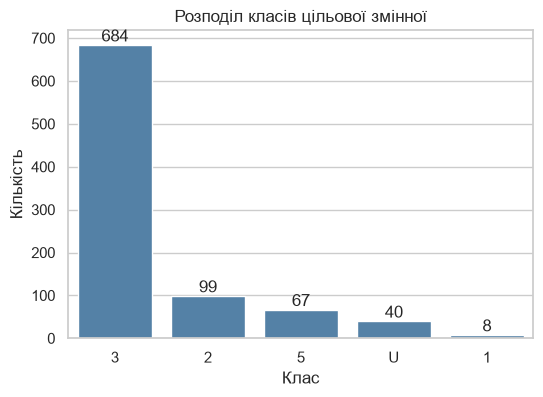

Мінімальна кількість об'єктів у класі: 8


In [4]:
counts = y.value_counts()
display(counts.to_frame('кількість'))
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color='steelblue')
ax.set_title('Розподіл класів цільової змінної'); ax.set_ylabel('Кількість'); ax.set_xlabel('Клас')
for i, v in enumerate(counts.values): ax.text(i, v, str(v), ha='center', va='bottom')
plt.show()

# рідкісні класи: залишаємо, якщо ≥ 2 об'єктів (мінімум для стратифікованого поділу)
too_rare = counts[counts < 2].index.tolist()
if too_rare:
    keep = ~y.isin(too_rare); X, y = X[keep], y[keep]
    print('Виключено класи з <2 об\'єктами:', too_rare)
print('Мінімальна кількість об\'єктів у класі:', y.value_counts().min())

**Рішення щодо рідкісних класів.** Розподіл: клас 3 — 684, клас 2 — 99, клас 5 — 67, клас U — 40, клас 1 — лише 8 об'єктів (клас 4 із документації в даних відсутній). Усі класи залишено: вони є частиною задачі, а macro F1 враховує кожен клас однаково. Наслідки для CV: після стратифікованого поділу клас 1 має 6 об'єктів у train і 2 у test; у 5-блочній CV у валідаційному блоці опиняється лише 1–2 його об'єкти, тому оцінки по блоках сильно шумлять. Внутрішня CV в Optuna має 3 блоки, щоб клас 1 потрапляв у кожен тренувальний блок.

In [5]:
def chi2_stat(flag, labels):
    tab = pd.crosstab(flag, labels).values
    tab = tab[:, tab.sum(0) > 0]
    exp = np.outer(tab.sum(1), tab.sum(0)) / tab.sum()
    return ((tab - exp) ** 2 / exp).sum(), tab

rng = np.random.default_rng(SEED)
top_missing = [c_ for c_ in miss.index if c_ in X.columns and 0 < X[c_].isna().mean() < 1][:5]
rows = []
for col in top_missing:
    flag = X[col].isna().values
    stat, tab = chi2_stat(flag, y.values)
    _, p_chi, _, expd = stats.chi2_contingency(tab)
    perm = np.array([chi2_stat(flag, rng.permutation(y.values))[0] for _ in range(2000)])
    p_mc = (1 + (perm >= stat).sum()) / (1 + len(perm))
    cramer = np.sqrt(stat / (tab.sum() * (min(tab.shape) - 1)))
    rows.append({'ознака': col, 'частка пропусків': round(X[col].isna().mean(), 3), 'χ²': round(stat, 2),
                 'p (χ²)': p_chi, 'p (Монте-Карло)': p_mc, "V Крамера": round(cramer, 3),
                 'частка клітинок з E<5': round((expd < 5).mean(), 2)})
    print(f'--- {col}: таблиця спряженості (рядки: не пропуск/пропуск) × клас')
    display(pd.crosstab(pd.Series(np.where(flag, 'пропуск', 'є значення'), name=col), y.rename('клас')))
mech = pd.DataFrame(rows); display(mech)
n_dep = (mech['p (Монте-Карло)'] < 0.05).sum()
print(f'Для {n_dep} із {len(mech)} ознак пропуски статистично пов\'язані з класом (α=0.05).')
print('Висновок:', 'пропуски НЕ схожі на MCAR — пов\'язані з класом (MAR/MNAR або структурні), індикатори пропусків можуть бути корисними.'
      if n_dep > 0 else 'підстав відкинути MCAR немає.')

--- bc: таблиця спряженості (рядки: не пропуск/пропуск) × клас


клас,1,2,3,5,U
bc,,,,,
пропуск,8,99,683,67,40
є значення,0,0,1,0,0


--- exptl: таблиця спряженості (рядки: не пропуск/пропуск) × клас


клас,1,2,3,5,U
exptl,,,,,
пропуск,6,99,684,67,40
є значення,2,0,0,0,0


--- blue%2Fbright%2Fvarn%2Fclean: таблиця спряженості (рядки: не пропуск/пропуск) × клас


...

клас,1,2,3,5,U
phos,,,,,
пропуск,8,99,684,60,40
є значення,0,0,0,7,0


--- packing: таблиця спряженості (рядки: не пропуск/пропуск) × клас


клас,1,2,3,5,U
packing,,,,,
пропуск,8,99,675,67,40
є значення,0,0,9,0,0


,ознака,частка пропусків,χ²,p (χ²),p (Монте-Карло),V Крамера,частка клітинок з E<5
0,bc,0.999,0.31,9.889453e-01,1.000000,0.019,0.5
1,exptl,0.998,223.00,4.246571e-47,0.000500,0.498,0.5
2,blue%2Fbright%2Fvarn%2Fclean,0.993,37.37,1.514610e-07,0.001999,0.204,0.5
3,phos,0.992,87.50,4.464519e-18,0.000500,0.312,0.4
4,packing,0.990,2.84,5.842109e-01,0.454773,0.056,0.4


Для 3 із 5 ознак пропуски статистично пов'язані з класом (α=0.05).
Висновок: пропуски НЕ схожі на MCAR — пов'язані з класом (MAR/MNAR або структурні), індикатори пропусків можуть бути корисними.


**Інтерпретація.** Для трьох із п'яти ознак із найбільшою часткою пропусків (`exptl`, `blue/bright/varn/clean`, `phos`) пропуск статистично пов'язаний із класом (p за Монте-Карло ≤ 0,002; V Крамера 0,50; 0,20; 0,31), для `bc` і `packing` зв'язок не виявлено (p = 1,00 та 0,45). Усі п'ять ознак мають понад 99 % пропусків, тобто лише 1–9 спостережуваних значень, а частота клітинок з очікуваним значенням < 5 становить 40–50 %, тому χ²-тест має низьку потужність і ми спираємося на p за Монте-Карло. Показово, що спостережувані значення зосереджені в одному класі (`exptl` — лише клас 1, `phos` — лише клас 5, `packing` — лише клас 3), тобто сам факт наявності значення вказує на клас. Висновок: пропуски **не схожі на MCAR** — вони пов'язані з класом (структурні пропуски, MAR/MNAR); за даними розрізнити MAR і MNAR неможливо. Тому індикатори пропусків можуть бути корисними.

In [6]:
le = LabelEncoder()
y_enc = le.fit_transform(y)
print(dict(zip(le.classes_, range(len(le.classes_)))))

{'1': 0, '2': 1, '3': 2, '5': 3, 'U': 4}


## 3.2 Поділ даних і пайплайн обробки

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED)
print(X_train.shape, X_test.shape)
print('Об\'єктів кожного класу у train/test:')
display(pd.DataFrame({'клас': le.classes_, 'train': np.bincount(y_train), 'test': np.bincount(y_test)}).set_index('клас').T)

def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'), make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        # error_on_new=False: у блоці, де в train пропусків не було, а у valid з'явились, не виникає помилки
        transformers.append(('miss', MissingIndicator(features='missing-only', error_on_new=False),
                             make_column_selector()))
    return ColumnTransformer(transformers)

def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)

def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([('prep', build_preprocessor(with_indicators)), ('clf', make_model(name, params))])

models = ['DT', 'RF', 'XGB']

(718, 31) (180, 31)
Об'єктів кожного класу у train/test:


клас,1,2,3,5,U
train,6,79,547,54,32
test,2,20,137,13,8


**Варіант A** — медіана/мода + one-hot. **Варіант B** — те саме + бінарні індикатори пропусків для ознак, що мали пропуски в тренувальних даних. Імпутація виконується тільки всередині `Pipeline`, тобто окремо для кожного тренувального блоку CV.

## 3.3 Базові моделі (типові гіперпараметри, повторна CV 5×3)

In [8]:
scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)   # ОДИН і той самий cv для всіх моделей
cv_res = {}
for v, wi in {'A': False, 'B': True}.items():
    for name in models:
        t0 = time.time()
        cv_res[(v, name)] = cross_validate(build_pipeline(name, with_indicators=wi), X_train, y_train,
                                           cv=cv, scoring=scoring)
        print(f'варіант {v}, {name}: {time.time()-t0:.1f} с')

fmt = lambda a: f'{np.mean(a):.4f} ± {np.std(a, ddof=1):.4f}'
def table_cv(v):
    return pd.DataFrame({name: {'Accuracy': fmt(cv_res[(v, name)]['test_acc']),
                                'Macro F1': fmt(cv_res[(v, name)]['test_f1m']),
                                'Balanced acc.': fmt(cv_res[(v, name)]['test_bacc'])} for name in models}).T
print('Таблиця 1. CV, варіант A (типові параметри)'); display(table_cv('A'))
print('Таблиця 2. CV, варіант B (типові параметри)'); display(table_cv('B'))

варіант A, DT: 0.3 с
варіант A, RF: 2.7 с
варіант A, XGB: 4.4 с
варіант B, DT: 0.3 с
варіант B, RF: 2.9 с
варіант B, XGB: 9.8 с
Таблиця 1. CV, варіант A (типові параметри)


,Accuracy,Macro F1,Balanced acc.
DT,0.9443 ± 0.0187,0.8984 ± 0.0746,0.9084 ± 0.0699
RF,0.9549 ± 0.0196,0.9468 ± 0.0230,0.9485 ± 0.0241
XGB,0.9517 ± 0.0191,0.9131 ± 0.0720,0.9155 ± 0.0669


Таблиця 2. CV, варіант B (типові параметри)


,Accuracy,Macro F1,Balanced acc.
DT,0.9963 ± 0.0074,0.9931 ± 0.0110,0.9944 ± 0.0113
RF,0.9977 ± 0.0043,0.9959 ± 0.0075,0.9994 ± 0.0011
XGB,0.9940 ± 0.0074,0.9623 ± 0.0725,0.9655 ± 0.0727


**Коментар до табл. 1–2.** У варіанті A моделі ще далекі від стелі: macro F1 дорівнює 0,898 (DT), 0,947 (RF) та 0,913 (XGB) при accuracy 0,944–0,955. Додавання індикаторів пропусків (варіант B) піднімає macro F1 до 0,993 (DT), 0,996 (RF) та 0,962 (XGB), а accuracy — до 0,994–0,998. Тож у варіанті B для DT і RF виникає ефект стелі, і різниці між ними малі порівняно з шумом. Різниця у macro F1 між A і B помітніша, ніж в accuracy, бо вона визначається рідкісними класами. XGBoost у варіанті B має найбільше стандартне відхилення (±0,0725): імовірно, у деяких блоках він помиляється на рідкісному класі, тому його середнє нижче, ніж у DT і RF. Статистична значущість цих відмінностей перевіряється в п. 3.5.

## 3.4 Підбір гіперпараметрів (Optuna) і вкладена крос-валідація

In [9]:
def suggest_params(trial, name):
    if name == 'DT':
        return {'max_depth': trial.suggest_int('max_depth', 2, 20),
                'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
                'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])}
    if name == 'RF':
        return {'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
                'max_depth': trial.suggest_int('max_depth', 3, 30),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
                'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
                'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample'])}
    return {  # XGB
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True)}

def tune(name, X_tr, y_tr, n_trials=N_TRIALS):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))     # у Optuna іде ВЕСЬ пайплайн
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

In [10]:
# Вкладена CV: зовнішній цикл — оцінка, внутрішній (tune) — підбір лише на тренувальній частині зовнішнього блоку
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested = {name: [] for name in models}
inner_best = {name: [] for name in models}
for name in models:
    t0 = time.time()
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(name, X_tr, y_tr)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        nested[name].append(f1_score(y_va, model.predict(X_va), average='macro'))
        inner_best[name].append(study.best_value)
    print(f'{name}: nested CV завершено за {time.time()-t0:.0f} с')

DT: nested CV завершено за 10 с
RF: nested CV завершено за 253 с
XGB: nested CV завершено за 255 с


In [11]:
# Фінальна оптимізація на всій тренувальній вибірці
studies, final_pipes = {}, {}
for name in models:
    studies[name] = tune(name, X_train, y_train)
    final_pipes[name] = build_pipeline(name, True, studies[name].best_params).fit(X_train, y_train)

t3 = pd.DataFrame({name: {
    'Nested CV macro F1 (зовн. 5 блоків)': fmt(nested[name]),
    'Сер. inner best_value (по зовн. блоках)': f'{np.mean(inner_best[name]):.4f}',
    'study.best_value (весь train)': f'{studies[name].best_value:.4f}',
    'best_value − nested': f'{studies[name].best_value - np.mean(nested[name]):+.4f}',
    'CV, B, типові параметри (macro F1)': fmt(cv_res[('B', name)]['test_f1m']),
    'Приріст nested − типові': f"{np.mean(nested[name]) - np.mean(cv_res[('B', name)]['test_f1m']):+.4f}"} for name in models}).T
print('Таблиця 3. Вкладена CV, варіант B, після оптимізації'); display(t3)
print('Таблиця 4. Найкращі гіперпараметри (Optuna)')
display(pd.DataFrame({name: studies[name].best_params for name in models}).T.fillna('—'))

Таблиця 3. Вкладена CV, варіант B, після оптимізації


,Nested CV macro F1 (зовн. 5 блоків),Сер. inner best_value (по зовн. блоках),study.best_value (весь train),best_value − nested,"CV, B, типові параметри (macro F1)",Приріст nested − типові
DT,0.8855 ± 0.1048,0.9415,0.9933,+0.1077,0.9931 ± 0.0110,-0.1076
RF,0.9925 ± 0.0095,0.9706,0.9938,+0.0013,0.9959 ± 0.0075,-0.0034
XGB,0.9775 ± 0.0425,0.9366,0.9938,+0.0163,0.9623 ± 0.0725,+0.0152


Таблиця 4. Найкращі гіперпараметри (Optuna)


,max_depth,min_samples_split,min_samples_leaf,class_weight,n_estimators,max_features,learning_rate,subsample,colsample_bytree,min_child_weight
DT,11.0,5.0,1.0,—,—,—,—,—,—,—
RF,12,—,2,balanced_subsample,450,0.5,—,—,—,—
XGB,4.0,—,—,—,361.0,—,0.160635,0.642542,0.92556,1.057692


**Коментар до табл. 3.** `study.best_value` — максимум із 30 зашумлених оцінок на тих самих даних, на яких обирались параметри, тому він оптимістично зміщений. Вкладена CV оцінює *процедуру* «підбір + навчання» на блоках, що в підборі не брали участі: зовнішній цикл оцінює не одну конкретну модель, а алгоритм разом із процедурою пошуку гіперпараметрів. Різниця `best_value − nested` становить +0,1077 для DT, +0,0013 для RF та +0,0163 для XGB. Для RF вона практично нульова: ліс майже нечутливий до гіперпараметрів і результат стабільний. Для XGB зміщення помірне, а для DT — дуже велике: nested-оцінка дерева (0,8855 ± 0,1048) значно нижча за `best_value` (0,9933) і навіть за результат із типовими параметрами (0,9931), тобто вибір параметрів 3-блочною внутрішньою CV на 4–5 об'єктах клас 1 є шумним, а одиночне дерево чутливе до нього. Частину різниці дає й те, що nested CV використовує 5 значень, а не 15, тож вона шумніша. Висновок: `best_value` не можна подавати як якість моделі.

Таблиця 4 показує знайдені параметри: DT — `max_depth = 11`, `min_samples_split = 5`, `min_samples_leaf = 1`; RF — 450 дерев, `max_depth = 12`, `min_samples_leaf = 2`, `max_features = 0.5`, `class_weight = 'balanced_subsample'`; XGB — 361 дерево, `max_depth = 4`, `learning_rate ≈ 0.16`, `subsample ≈ 0.64`, `min_child_weight ≈ 1.06`.

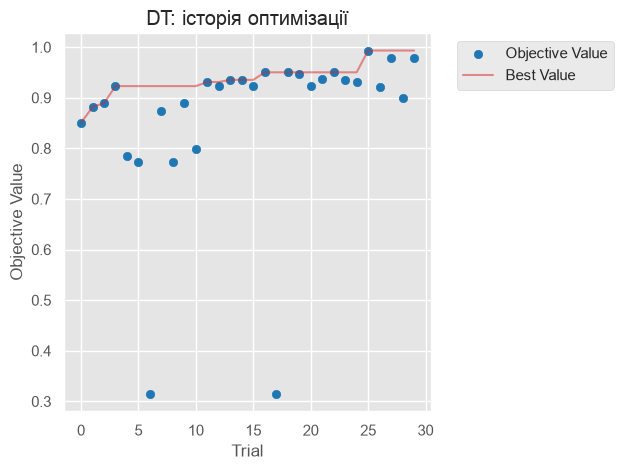

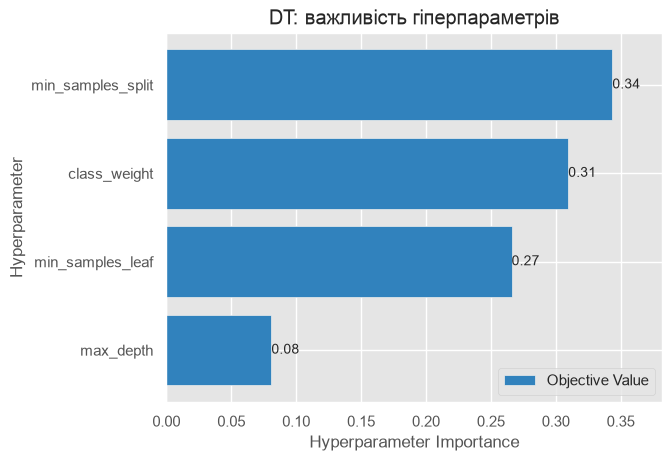

DT: найкраще значення 0.9933; перше досягнуто на спробі 25; частка спроб, що досягли максимуму: 0.03


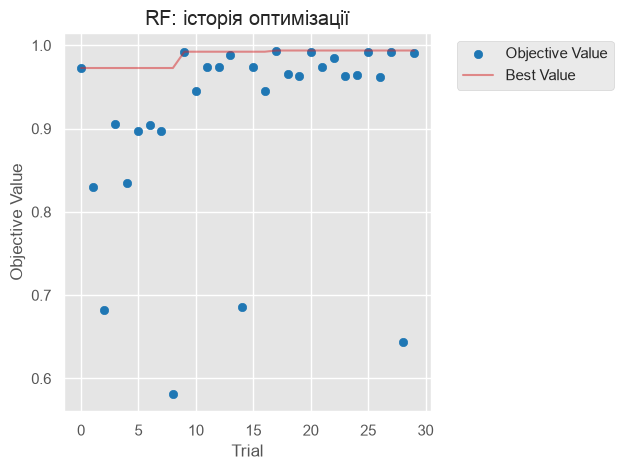

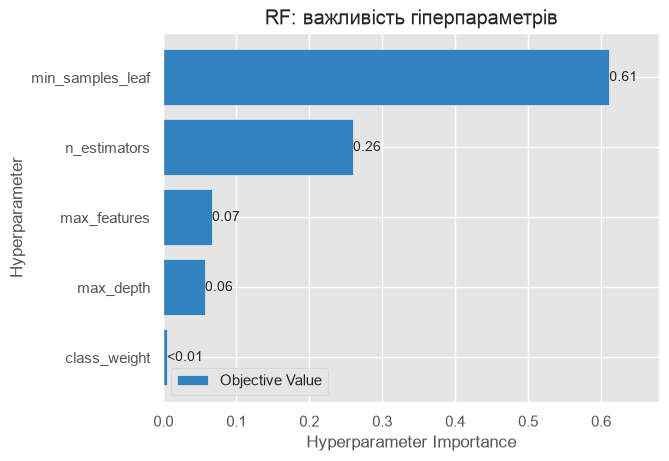

RF: найкраще значення 0.9938; перше досягнуто на спробі 17; частка спроб, що досягли максимуму: 0.03


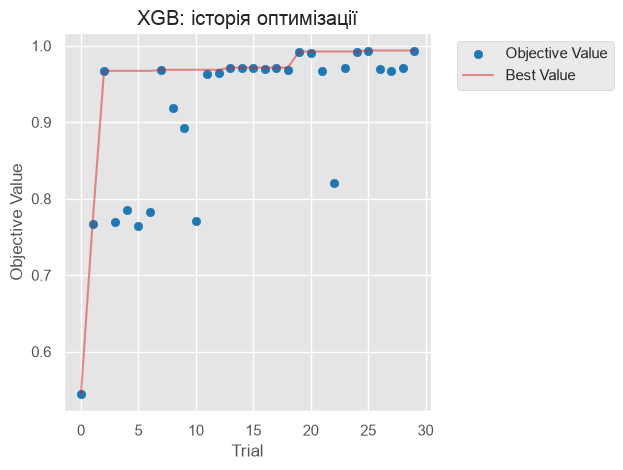

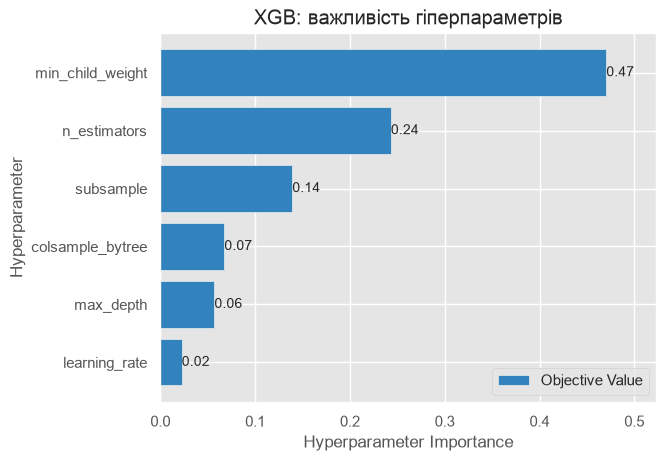

XGB: найкраще значення 0.9938; перше досягнуто на спробі 25; частка спроб, що досягли максимуму: 0.07


In [12]:
import optuna.visualization.matplotlib as ovm

def set_clean_title(ax, text):
    for loc in ('left', 'center', 'right'):
        ax.set_title('', loc=loc)      # прибираємо власні заголовки Optuna
    ax.set_title(text)                 # ставимо свій

for name in models:
    ax = ovm.plot_optimization_history(studies[name])
    set_clean_title(ax, f'{name}: історія оптимізації'); plt.show()
    try:
        ax = ovm.plot_param_importances(studies[name])
        set_clean_title(ax, f'{name}: важливість гіперпараметрів'); plt.show()
    except Exception as e:
        print(f'{name}: важливість параметрів не обчислена ({type(e).__name__}) — зазвичай через однакові значення цільової функції (ефект стелі).')
    vals = np.array([t.value for t in studies[name].trials])
    print(f'{name}: найкраще значення {vals.max():.4f}; перше досягнуто на спробі {vals.argmax()}; '
          f'частка спроб, що досягли максимуму: {(vals >= vals.max() - 1e-12).mean():.2f}')

**Коментар до оптимізації.** Оптимізація збіглася не повністю: найкраще значення знайдено на пізніх спробах (25-та для DT та XGB, 17-та для RF із 30), і лише 1–2 спроби досягли максимуму (3 % для DT і RF, 7 % для XGB). Значення цільової функції в багатьох спробах дуже близькі (≈ 0,99), тож максимум — це радше найкраща з кількох майже рівноцінних конфігурацій, що узгоджується з оптимістичним зміщенням `best_value`. За `plot_param_importances` найважливішими є: для DT — `min_samples_split` (0,34), `class_weight` (0,31) та `min_samples_leaf` (0,27); для RF — `min_samples_leaf` (0,61) та `n_estimators` (0,26); для XGB — `min_child_weight` (0,47) і `n_estimators` (0,24), тоді як `learning_rate` майже не впливає (0,02). Тобто найбільше значення мають параметри, що регулюють мінімальний розмір листка/вузла, — вони визначають, чи зможе модель виділити рідкісні класи.

## 3.5 Статистичне порівняння (скоригований t-тест Наде–Бенжіо)

In [13]:
def nadeau_bengio(a, b, ntest_ntrain=1/4):
    d = np.asarray(a) - np.asarray(b); kr = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return d.mean(), np.nan, (1.0 if d.mean() == 0 else 0.0)
    t = d.mean() / np.sqrt(var * (1 / kr + ntest_ntrain))
    return d.mean(), t, 2 * stats.t.sf(abs(t), kr - 1)

f1 = lambda v, n: cv_res[(v, n)]['test_f1m']
rows = []
for name in models:
    dbar, t, p = nadeau_bengio(f1('B', name), f1('A', name))
    rows.append({'Порівняння': f'{name}: B vs A', 'd̄': dbar, 't': t, 'p': p,
                 'Висновок': 'значуща' if p < 0.05 else 'незначуща'})
best2 = sorted(models, key=lambda n: -np.mean(f1('B', n)))[:2]
dbar, t, p = nadeau_bengio(f1('B', best2[0]), f1('B', best2[1]))
rows.append({'Порівняння': f'B: {best2[0]} vs {best2[1]}', 'd̄': dbar, 't': t, 'p': p,
             'Висновок': 'значуща' if p < 0.05 else 'незначуща'})
t5 = pd.DataFrame(rows); print('Таблиця 5. Тест Наде–Бенжіо (macro F1, α = 0.05, kr = 15, df = 14)')
display(t5.round({'d̄': 4, 't': 3, 'p': 4}))

Таблиця 5. Тест Наде–Бенжіо (macro F1, α = 0.05, kr = 15, df = 14)


,Порівняння,d̄,t,p,Висновок
0,DT: B vs A,0.0947,2.224,0.0431,значуща
1,RF: B vs A,0.0492,4.041,0.0012,значуща
2,XGB: B vs A,0.0492,3.890,0.0016,значуща
3,B: RF vs DT,0.0028,0.684,0.5052,незначуща


**Коментар до табл. 5.** Блоки CV перетинаються за тренувальними даними, тому оцінки залежні, і звичайний парний t-тест занижує дисперсію; поправка Наде–Бенжіо додає до `1/(kr)` величину `n_test/n_train = 1/4`. Індикатори пропусків (B проти A) дають значуще зростання macro F1 для всіх трьох моделей: DT (d̄ = +0,0947, p = 0,043), RF (d̄ = +0,0492, p = 0,0012), XGB (d̄ = +0,0492, p = 0,0016). Для DT значущість межова; якщо врахувати поправку Бонферроні на три порівняння (α = 0,0167), значущими лишаються RF і XGB. Між двома найкращими моделями варіанта B — RF і DT — різниця незначуща (d̄ = +0,0028, p = 0,505): за CV переваги RF над DT не доведено.

## 3.6 Фінальна оцінка на тестовій вибірці

Таблиця 6. Фінальні моделі (варіант B, після оптимізації) на тестовій вибірці


,Accuracy,Macro F1,Balanced acc.
DT,0.9611,0.8699,0.8356
RF,0.9722,0.8846,0.8385
XGB,0.9778,0.8970,0.8485


Найкраща модель на тесті: XGB
              precision    recall  f1-score   support

           1       1.00      0.50      0.67         2
           2       0.95      1.00      0.98        20
           3       0.98      0.99      0.99       137
           5       1.00      1.00      1.00        13
           U       1.00      0.75      0.86         8

    accuracy                           0.98       180
   macro avg       0.99      0.85      0.90       180
weighted avg       0.98      0.98      0.98       180



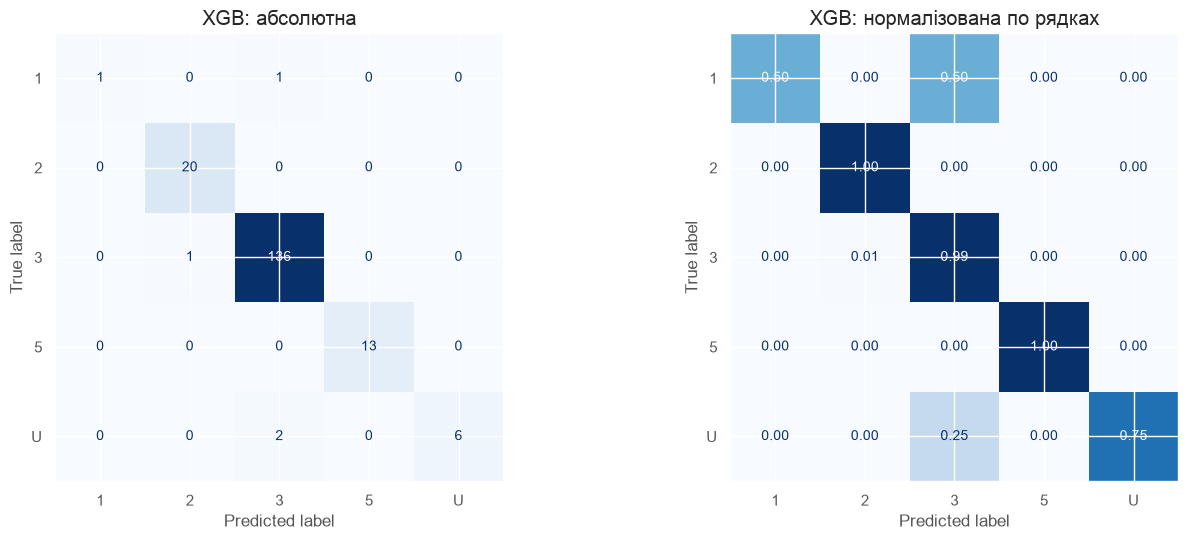

Найчастіше плутаються (справжній → прогноз, кількість): [('U', '3', np.int64(2)), ('1', '3', np.int64(1)), ('3', '2', np.int64(1))]
Кількість тестових об'єктів по класах: {'1': np.int64(2), '2': np.int64(20), '3': np.int64(137), '5': np.int64(13), 'U': np.int64(8)}


In [14]:
pred_test = {n: final_pipes[n].predict(X_test) for n in models}
t6 = pd.DataFrame({n: {'Accuracy': accuracy_score(y_test, pred_test[n]),
                       'Macro F1': f1_score(y_test, pred_test[n], average='macro'),
                       'Balanced acc.': balanced_accuracy_score(y_test, pred_test[n])} for n in models}).T
print('Таблиця 6. Фінальні моделі (варіант B, після оптимізації) на тестовій вибірці'); display(t6.round(4))
best_name = t6['Macro F1'].idxmax(); print('Найкраща модель на тесті:', best_name)

labels = np.arange(len(le.classes_))
print(classification_report(y_test, pred_test[best_name], labels=labels, target_names=le.classes_, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test[best_name], labels=labels, display_labels=le.classes_,
                                        ax=ax[0], colorbar=False, cmap='Blues'); ax[0].set_title(f'{best_name}: абсолютна')
ConfusionMatrixDisplay.from_predictions(y_test, pred_test[best_name], labels=labels, display_labels=le.classes_,
                                        normalize='true', values_format='.2f', ax=ax[1], colorbar=False, cmap='Blues')
ax[1].set_title(f'{best_name}: нормалізована по рядках'); plt.tight_layout(); plt.show()

cm = confusion_matrix(y_test, pred_test[best_name], labels=labels)
conf = [(le.classes_[i], le.classes_[j], cm[i, j]) for i in labels for j in labels if i != j and cm[i, j] > 0]
conf = sorted(conf, key=lambda x: -x[2])
print('Найчастіше плутаються (справжній → прогноз, кількість):', conf if conf else 'помилок на тесті немає')
print('Кількість тестових об\'єктів по класах:', dict(zip(le.classes_, np.bincount(y_test, minlength=len(labels)))))

**Чому тест відрізняється від CV.** На тесті macro F1 дорівнює 0,870 (DT), 0,885 (RF) та 0,897 (XGB) проти 0,99 у CV, хоча accuracy лишається високою (0,961–0,978). Причина — кількість об'єктів найменших класів: у тесті клас 1 має лише 2 об'єкти, клас U — 8. Один пропущений об'єкт класу 1 дає recall 0,50 і F1 0,67 (втрата ≈ 0,07 від macro F1), а два пропущені об'єкти класу U — F1 0,86 (≈ 0,03), що разом пояснює більшу частину падіння від 0,99 до 0,90. CV усереднює 15 блоків, а тест — це одна реалізація з дуже широким довірчим інтервалом, тому різниця між моделями на тесті (0,870–0,897) — це один-два об'єкти й не є доказом переваги XGBoost.

Найкраща на тесті модель — XGB. Найчастіші помилки: U → 3 (2 об'єкти), 1 → 3 (1) та 3 → 2 (1), тобто рідкісні класи плутаються з домінантним класом 3 (684 об'єкти). Класи 2 та 5 класифікуються майже ідеально (F1 0,98 і 1,00).

## 3.7 Інтерпретація: важливість ознак

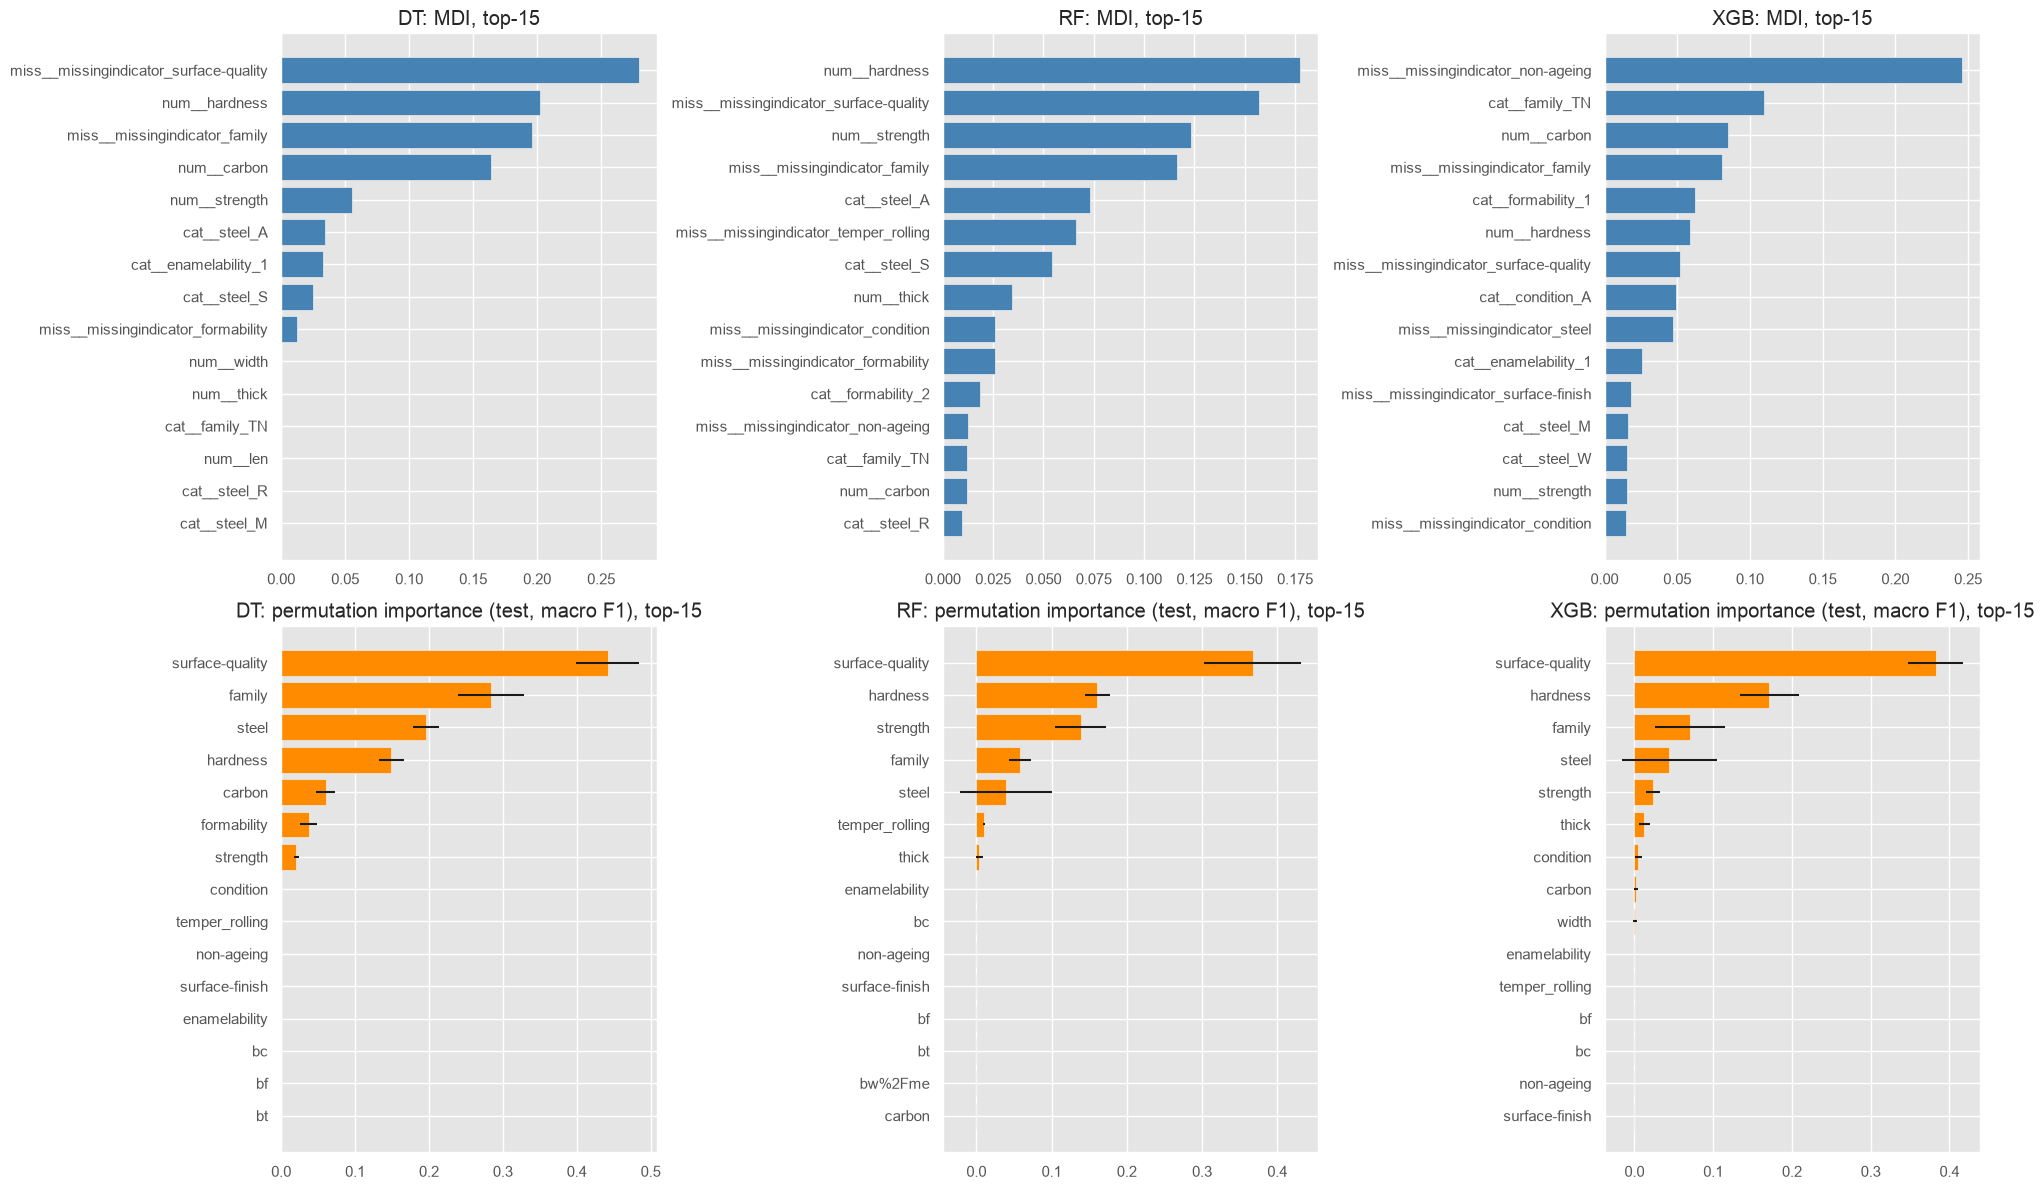

In [15]:
def orig_of(fname, cols):
    # відновлення початкової ознаки за назвою після ColumnTransformer
    if fname.startswith('miss__missingindicator_'):
        return fname[len('miss__missingindicator_'):]
    base = fname.split('__', 1)[1] if fname.startswith('num__') else fname[len('cat__onehot__'):]
    if fname.startswith('num__'): return base
    cands = [c_ for c_ in cols if base.startswith(c_ + '_')]
    return max(cands, key=len) if cands else base

cols = list(X_train.columns)
mdi, perm = {}, {}
for n in models:
    pipe = final_pipes[n]
    names = pipe.named_steps['prep'].get_feature_names_out()
    mdi[n] = pd.Series(pipe.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
    r = permutation_importance(pipe, X_test, y_test, scoring='f1_macro', n_repeats=15, random_state=SEED, n_jobs=-1)
    perm[n] = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
    perm[n + '_std'] = pd.Series(r.importances_std, index=X_test.columns).reindex(perm[n].index)

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for j, n in enumerate(models):
    top = mdi[n].head(15)[::-1]
    axes[0, j].barh(top.index, top.values, color='steelblue'); axes[0, j].set_title(f'{n}: MDI, top-15')
    tp = perm[n].head(15)[::-1]
    axes[1, j].barh(tp.index, tp.values, xerr=perm[n + '_std'].reindex(tp.index).values, color='darkorange')
    axes[1, j].set_title(f'{n}: permutation importance (test, macro F1), top-15')
plt.tight_layout(); plt.show()

In [16]:
for n in models:
    top15 = mdi[n].head(15)
    ind = [f for f in top15.index if f.startswith('miss__')]
    print(f'{n}: індикаторів пропусків у top-15 MDI: {len(ind)}  {ind}')
    print(f'    сумарна MDI-частка всіх індикаторів: {mdi[n][[f for f in mdi[n].index if f.startswith("miss__")]].sum():.3f}')

# узгодженість MDI та permutation importance (MDI агрегована до початкових ознак)
agg = {n: mdi[n].groupby([orig_of(f, cols) for f in mdi[n].index]).sum().reindex(cols).fillna(0) for n in models}
cons = pd.DataFrame({n: {'Spearman(MDI, perm)': stats.spearmanr(agg[n], perm[n].reindex(cols).fillna(0))[0]} for n in models}).T
print('Узгодженість MDI та permutation importance:'); display(cons.round(3))
tops = pd.DataFrame({n: list(agg[n].sort_values(ascending=False).index[:5]) for n in models}); print('Top-5 початкових ознак за MDI:'); display(tops)
tops_p = pd.DataFrame({n: list(perm[n].index[:5]) for n in models}); print('Top-5 за permutation importance:'); display(tops_p)

DT: індикаторів пропусків у top-15 MDI: 3  ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_formability']
    сумарна MDI-частка всіх індикаторів: 0.487
RF: індикаторів пропусків у top-15 MDI: 6  ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_temper_rolling', 'miss__missingindicator_condition', 'miss__missingindicator_formability', 'miss__missingindicator_non-ageing']
    сумарна MDI-частка всіх індикаторів: 0.418
XGB: індикаторів пропусків у top-15 MDI: 6  ['miss__missingindicator_non-ageing', 'miss__missingindicator_family', 'miss__missingindicator_surface-quality', 'miss__missingindicator_steel', 'miss__missingindicator_surface-finish', 'miss__missingindicator_condition']
    сумарна MDI-частка всіх індикаторів: 0.504
Узгодженість MDI та permutation importance:


,"Spearman(MDI, perm)"
DT,0.893
RF,0.352
XGB,0.568


Top-5 початкових ознак за MDI:


,DT,RF,XGB
0,surface-quality,hardness,non-ageing
1,hardness,surface-quality,carbon
2,family,strength,family
3,carbon,family,hardness
4,strength,temper_rolling,surface-quality


Top-5 за permutation importance:


,DT,RF,XGB
0,surface-quality,surface-quality,surface-quality
1,family,hardness,hardness
2,steel,strength,family
3,hardness,family,steel
4,carbon,steel,strength


**Відповіді на запитання за отриманими результатами.**

* *Індикатори пропусків у top-15 за MDI.* Так: їх 3 у DT (`surface-quality`, `family`, `formability`), 6 у RF і 6 в XGB (серед них `surface-quality`, `family`, `condition`, `non-ageing`). Сумарно індикатори мають 49 % (DT), 42 % (RF) та 50 % (XGB) усієї MDI-важливості. Це узгоджується з п. 3.1: пропуски пов'язані з класом (не MCAR; за документацією датасету частина пропусків структурна — ознака не застосовна до даного виробу), тож факт пропуску несе інформацію про клас. Збігається і зі значущим приростом якості у варіанті B (табл. 5).
* *Узгодженість MDI та permutation importance.* Кореляція Спірмена (MDI, агрегована до початкових ознак, проти permutation) дорівнює 0,89 для DT, 0,57 для XGB та лише 0,35 для RF. Permutation importance в усіх моделей очолює `surface-quality`, далі, у різному порядку, `hardness`, `family`, `steel`, `strength`; за MDI першими стають `surface-quality` (DT), `hardness` (RF) та `non-ageing` (XGB), а числові `carbon`, `hardness`, `strength` піднімаються вище. MDI рахується на тренувальних даних і зміщена на користь ознак із великою кількістю унікальних значень (числових), для яких існує багато порогів розбиття [10]. Permutation importance рахується на тесті і відображає внесок у якість, але вона перемішує початковий стовпець разом з його пропусками, тож для ознаки з індикатором вона вимірює сумарний внесок значення й факту пропуску; крім того, при 180 тестових об'єктах і рідкісних класах багато значень близькі до нуля.
* *Чому важливості однієї ознаки різні в DT, RF і XGB.* Одиночне дерево жадібно обирає одну з кількох взаємозамінних ознак і ігнорує решту; RF через випадковий вибір ознак у вузлі розподіляє важливість між замінниками (наприклад, `temper_rolling` потрапила в top-5 лише в RF); бустинг послідовно виправляє залишки й концентрує важливість в інших ознаках (`non-ageing` — перша в XGB, але не в top-5 в DT та RF). Тож розбіжність у важливостях відображає різні стратегії побудови моделей і корельованість ознак.

## 3.8 Аналіз розбіжностей між моделями

In [17]:
dec = lambda a: le.inverse_transform(np.asarray(a))
P = np.vstack([pred_test[n] for n in models])
idx_test = np.where(~(P == P[0]).all(axis=0))[0]
rows = [{'Джерело': 'test', 'Об\'єкт': f'#{X_test.index[i]}', '_split': 'test', '_pos': i,
         'Справжній клас': dec([y_test[i]])[0], **{n: dec([pred_test[n][i]])[0] for n in models}} for i in idx_test]
print(f'Розбіжностей у тестовій вибірці: {len(rows)}')

if len(rows) < 3:
    print('Розбіжностей <3: доповнюємо out-of-fold прогнозами на тренувальній вибірці (cross_val_predict)!')
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    oof = {n: cross_val_predict(clone(final_pipes[n]), X_train, y_train, cv=skf) for n in models}
    Po = np.vstack([oof[n] for n in models])
    for i in np.where(~(Po == Po[0]).all(axis=0))[0]:
        if len(rows) >= 5: break
        rows.append({'Джерело': 'train (OOF)', 'Об\'єкт': f'#{X_train.index[i]}', '_split': 'train', '_pos': i,
                     'Справжній клас': dec([y_train[i]])[0], **{n: dec([oof[n][i]])[0] for n in models}})
t7 = pd.DataFrame(rows)
print('Таблиця 7. Об\'єкти розбіжностей (DT / RF / XGB)')
display(t7.drop(columns=['_split', '_pos']).rename(columns={'DT': 'Decision Tree', 'RF': 'Random Forest', 'XGB': 'XGBoost'}))
if len(t7) < 3:
    print('УВАГА: навіть з OOF знайдено менше 3 об\'єктів розбіжності (сильний ефект стелі).')

Розбіжностей у тестовій вибірці: 5
Таблиця 7. Об'єкти розбіжностей (DT / RF / XGB)


,Джерело,Об'єкт,Справжній клас,Decision Tree,Random Forest,XGBoost
0,test,#110,3,2,3,3
1,test,#585,3,2,3,2
2,test,#619,3,U,U,3
3,test,#682,2,3,3,2
4,test,#24,1,2,3,3


In [18]:
if len(t7) == 0:
    print('Об\'єктів розбіжності немає — детальний аналіз неможливий.')
else:
    sel = t7.iloc[0]
    Xsrc = X_test if sel['_split'] == 'test' else X_train
    row = Xsrc.iloc[[int(sel['_pos'])]]
    print(f"Аналізований об'єкт: {sel['Об\'єкт']} ({sel['Джерело']}), справжній клас: {sel['Справжній клас']}")
    if sel['_split'] == 'train':
        print('Примітка: об\'єкт з тренувальної вибірки; пояснення робляться для фінальних моделей, які його бачили в навчанні.')

    prep = final_pipes['DT'].named_steps['prep']
    num_cols, cat_cols = list(prep.transformers_[0][2]), list(prep.transformers_[1][2])
    fill = {**dict(zip(num_cols, prep.named_transformers_['num'].statistics_)),
            **dict(zip(cat_cols, prep.named_transformers_['cat'].named_steps['impute'].statistics_))}
    raw = row.iloc[0]
    det = pd.DataFrame({'ознака': raw.index, 'початкове значення': raw.values, 'пропущено': raw.isna().values})
    det['значення після імпутації'] = [fill[c_] if m_ else v for c_, v, m_ in zip(det['ознака'], det['початкове значення'], det['пропущено'])]
    with pd.option_context('display.max_rows', None): display(det)
    print('Пропущені ознаки та значення, якими їх заповнено:'); display(det[det['пропущено']][['ознака', 'значення після імпутації']])

Аналізований об'єкт: #110 (test), справжній клас: 3


,ознака,початкове значення,пропущено,значення після імпутації
0,family,NaN,True,TN
1,steel,NaN,True,A
2,carbon,0,False,0
3,hardness,0,False,0
4,temper_rolling,T,False,T
5,condition,S,False,S
6,formability,2,False,2
7,strength,0,False,0
8,non-ageing,NaN,True,N
9,surface-finish,NaN,True,P


Пропущені ознаки та значення, якими їх заповнено:


,ознака,значення після імпутації
0,family,TN
1,steel,A
8,non-ageing,N
9,surface-finish,P
10,surface-quality,E
11,enamelability,2
12,bc,Y
13,bf,Y
14,bt,Y
15,bw%2Fme,B


predict_proba:


,1,2,3,5,U
DT,0.000,1.000,0.000,0.000,0.000
RF,0.002,0.337,0.485,0.176,0.000
XGB,0.113,0.200,0.591,0.045,0.051


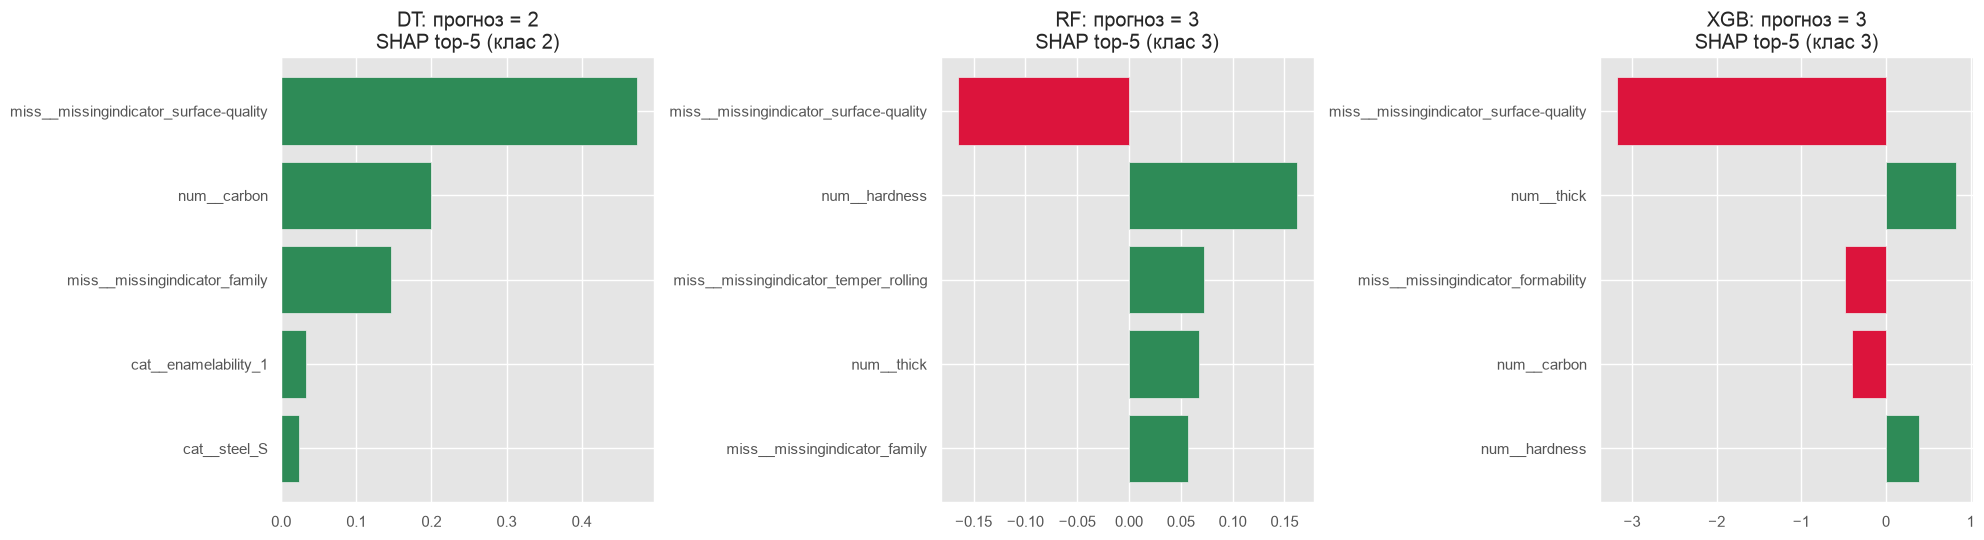

--- DT


,SHAP
miss__missingindicator_surface-quality,0.473224
num__carbon,0.199166
miss__missingindicator_family,0.146650
cat__enamelability_1,0.032549
cat__steel_S,0.023165


--- RF


,SHAP
miss__missingindicator_surface-quality,-0.165374
num__hardness,0.162001
miss__missingindicator_temper_rolling,0.072313
num__thick,0.067348
miss__missingindicator_family,0.057076


--- XGB


,SHAP
miss__missingindicator_surface-quality,-3.176255
num__thick,0.831665
miss__missingindicator_formability,-0.480257
num__carbon,-0.401969
num__hardness,0.389384


Ознаки, спільні для top-5 усіх трьох моделей: {'miss__missingindicator_surface-quality'}
Серед top-5 є індикатори пропусків: {'DT': ['miss__missingindicator_surface-quality', 'miss__missingindicator_family'], 'RF': ['miss__missingindicator_surface-quality', 'miss__missingindicator_temper_rolling', 'miss__missingindicator_family'], 'XGB': ['miss__missingindicator_surface-quality', 'miss__missingindicator_formability']}


In [19]:
if len(t7) > 0:
    proba = {n: final_pipes[n].predict_proba(row)[0] for n in models}
    print('predict_proba:'); display(pd.DataFrame(proba, index=le.classes_[final_pipes['DT'].named_steps['clf'].classes_]).T.round(3))

    def shap_for_pred(pipe, row):
        p_, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
        xt = p_.transform(row); pred = clf.predict(xt)[0]
        sv = shap.TreeExplainer(clf).shap_values(xt, check_additivity=False)
        sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)    # (n, features, classes)
        k = list(clf.classes_).index(pred)
        return pd.Series(sv[0, :, k], index=p_.get_feature_names_out()), pred, xt[0]

    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5)); top5 = {}
    for ax, n in zip(axes, models):
        s, pred, xt = shap_for_pred(final_pipes[n], row)
        t5s = s.reindex(s.abs().sort_values(ascending=False).index).head(5); top5[n] = t5s
        ax.barh(t5s.index[::-1], t5s.values[::-1], color=['crimson' if v < 0 else 'seagreen' for v in t5s.values[::-1]])
        ax.set_title(f'{n}: прогноз = {le.classes_[pred]}\nSHAP top-5 (клас {le.classes_[pred]})')
    plt.tight_layout(); plt.show()
    for n in models: print(f'--- {n}'); display(top5[n].to_frame('SHAP'))
    common = set.intersection(*[set(top5[n].index) for n in models])
    print('Ознаки, спільні для top-5 усіх трьох моделей:', common if common else 'немає')
    print('Серед top-5 є індикатори пропусків:', {n: [f for f in top5[n].index if f.startswith('miss__')] for n in models})

**Аналіз розбіжностей.** У тесті знайдено 5 об'єктів розбіжності (#110, #585, #619, #682, #24), тож доповнювати їх out-of-fold прогнозами не довелось. Правильний клас прогнозував: DT — жодного разу, RF — для 2 із 5 (#110, #585), XGB — для 3 із 5 (#110, #619, #682); об'єкт #24 (клас 1, найрідкісніший) не вгадала жодна модель.

Детально розглянуто об'єкт **#110** (справжній клас 3). У нього пропущено 20 із 31 ознак; серед них `family`, `steel`, `surface-quality`, `surface-finish`, `enamelability` заповнено модою (`TN`, `A`, `E`, `P`, `2`), а числові значення (`carbon`, `hardness`, `thick`, `width`) були відомі. Прогнози: DT — клас 2 (імовірність 1,00), RF — клас 3 (0,485 проти 0,337 для класу 2), XGB — клас 3 (0,591 проти 0,200).

1. *Імпутовані значення та індикатори.* Єдина ознака, спільна для top-5 SHAP усіх трьох моделей, — індикатор `missingindicator_surface-quality`. У DT він дає +0,47 до класу 2, у RF −0,17 та в XGB −3,18 (у лог-шансах) проти класу 3: тобто в усіх трьох моделей відсутність `surface-quality` зсуває прогноз від класу 3, а в дерева — прямо до класу 2. Також DT враховує імпутовані `enamelability` (`enamelability_1`) та `steel` (`steel_S`) і індикатор `family`, тобто частково спирається на штучно підставлені значення.
2. *«Жорсткий» поріг проти усереднення.* Дерево доходить до чистого листка класу 2 по єдиному шляху (імовірність 1,00) і «впевнено помиляється». RF і XGB зважують інші ознаки (`hardness`, `thick`, `carbon`), які вказують на клас 3, і ці внески переважають сильний, але одиничний сигнал індикатора.
3. *Близькість до межі класів.* Імовірності RF (0,485 / 0,337) і XGB (0,591 / 0,200) показують, що об'єкт лежить близько до межі класів 2 і 3, тому правильний прогноз ансамблів тримається на невеликому запасі. Масштаби SHAP різні: для DT і RF це внески в імовірність, для XGB — у лог-шансах, тож абсолютні значення порівнювати не можна, лише знаки та порядок ознак.

## Висновок

1. Найкращою за macro F1 у крос-валідації є Random Forest — 0,9959 ± 0,0075 (варіант B, типові параметри) і 0,9925 ± 0,0095 у вкладеній CV, причому саме він найстабільніший (DT: 0,9931 ± 0,0110; XGBoost: 0,9623 ± 0,0725), але його перевага над DT статистично незначуща (d̄ = +0,0028, p = 0,505), а на тесті найвищий macro F1 має XGBoost (0,897 проти 0,885 у RF і 0,870 у DT), що відображає різницю в 1–2 об'єкти найменших класів, тож однозначного переможця немає.
2. Індикатори пропусків істотно покращили всі моделі (macro F1 для DT 0,898 → 0,993, для RF 0,947 → 0,996, для XGB 0,913 → 0,962; p = 0,043, 0,0012 і 0,0016, причому після поправки Бонферроні значущість зберігається лише для RF і XGB), що узгоджується з аналізом механізму (для 3 із 5 найрідших ознак пропуски пов'язані з класом, тобто не MCAR) і з важливостями: індикатори забезпечують 42–50 % сумарної MDI-важливості, а `surface-quality` та `family` лідирують і за permutation importance.
3. `best_value` перевищує оцінку вкладеної CV на +0,108 для DT, +0,001 для RF і +0,016 для XGB, тобто ризик оптимістичної оцінки найбільший для чутливого до параметрів одиночного дерева, а для RF він практично відсутній.
4. Приріст після оптимізації отримав лише XGBoost (+0,015: з 0,9623 до 0,9775), але він менший за стандартне відхилення оцінки, тоді як для DT (−0,108) та RF (−0,003) вкладена оцінка не перевищила результат із типовими параметрами, оскільки підбір за 3-блочною внутрішньою CV на малих класах шумний, а типові параметри дерева й лісу вже майже оптимальні.
5. Найскладнішими класами є клас 1 (лише 8 об'єктів, на тесті 2; recall 0,50) і клас U (recall 0,75), які плутаються з домінантним класом 3 (U → 3 двічі, 1 → 3 один раз), тоді як класи 2 і 5 класифікуються майже ідеально.
6. Аналіз 5 тестових об'єктів розбіжності показав, що DT не прогнозував правильно жодного з них, XGB — 3, RF — 2, а на об'єкті #110 (20 із 31 ознак імпутовано) одиничне дерево впевнено (з імовірністю 1,00) вибрало клас 2 через сигнал індикатора `surface-quality`, тоді як ансамблі усереднили його з іншими ознаками й дали правильний клас 3.
7. Для практичного використання доцільно обрати Random Forest: він має найвищу й найстабільнішу якість у CV, майже не потребує налаштування й значно дешевший за XGBoost (4,8 с проти 25,3 с на повну CV варіанту B) та інтерпретований через важливості ознак, тоді як XGBoost нестабільний (±0,07) і найдорожчий у підборі, а DT, найпрозоріший, після налаштування є ненадійним (0,886 ± 0,105).

## Відповіді на контрольні питання

1. **RF проти дерева.** Одне глибоке дерево має низьке зміщення й високу дисперсію. RF усереднює багато дерев на bootstrap-вибірках із випадковим підбором ознак: дисперсія середнього ≈ ρσ² + (1−ρ)σ²/B, тому ключ — **декореляція дерев** (малий ρ); зміщення майже не змінюється.
2. **Бустинг vs беггінг.** Беггінг будує незалежні дерева паралельно й зменшує дисперсію; бустинг — послідовно, кожне нове дерево виправляє помилки попередніх, зменшуючи зміщення. До перенавчання зі зростанням кількості дерев схильніший бустинг (потрібні `learning_rate`, ранній стоп, регуляризація); RF із ростом дерев майже не перенавчається.
3. **macro F1 / balanced accuracy.** При дисбалансі accuracy визначається домінантним класом; macro F1 і balanced accuracy рівноправно враховують класи. Macro — просте середнє F1 по класах, weighted — зважене кількістю об'єктів (тому ближче до accuracy).
4. **MCAR/MAR/MNAR.** MCAR — пропуск не залежить ні від чого; MAR — від спостережуваних ознак; MNAR — від самого пропущеного значення. Індикатори найкорисніші при MNAR та структурних пропусках (пропуск несе інформацію). З даних MAR від MNAR однозначно відрізнити не можна — потрібні неспостережувані значення.
5. **Витік.** Імпутація/кодування/масштабування до поділу чи CV; підбір гіперпараметрів на оброблених заздалегідь даних; використання тесту в цільовій функції. Запобігання: все в `Pipeline`, тест лише раз наприкінці, nested CV.
6. **best_value і nested CV.** best_value — максимум серед шумних оцінок на тих самих даних (selection bias). У nested CV зовнішній цикл оцінює *процедуру* підбору: на кожному зовнішньому блоці параметри підбираються лише на його train-частині, а оцінюється валід-частина; тобто оцінюється алгоритм+пошук, а не одна конкретна модель.
7. **Наде–Бенжіо.** Оцінки на блоках залежні (спільні тренувальні дані), парний t-тест занижує дисперсію та дає завелику кількість хибних значущостей. Поправка замінює 1/(kr) на 1/(kr) + n_test/n_train, збільшуючи стандартну похибку.
8. **MDI vs permutation.** MDI — сумарне зменшення неоднорідності на тренувальних даних (зміщена до ознак із багатьма значеннями); permutation — падіння метрики при перемішуванні ознаки (на тесті, модельно-агностична). Корельовані ознаки розмивають MDI між собою, а при permutation — занижують важливість кожної, бо дублер компенсує.
9. **SHAP.** Значення Шеплі для ознак; адитивність: f(x) = φ₀ + Σφᵢ. Локальне пояснення стосується одного об'єкта, глобальна важливість — це агрегація (наприклад, середнє |φ|) по набору.
10. **XGBoost і пропуски.** Sparsity-aware split finding: для кожного розбиття алгоритм пробує відправити всі пропуски ліворуч і праворуч і вибирає напрям із більшим приростом якості; напрям за замовчуванням вчиться з даних.
11. **Optuna.** TPE моделює розподіли «добрих» і «поганих» значень параметрів і семплює там, де ймовірніший успіх, на відміну від повного перебору (GridSearch) і випадкового пошуку; є прунінг неперспективних спроб, умовні простори пошуку та зручна візуалізація.